 Đề tài: Phân tích và dự đoán sức khỏe tâm thần thanh thiếu niên - Uruguay

Sức khỏe tâm thần ở thanh thiếu niên là một vấn đề quan trọng, có ảnh hưởng đến chất lượng cuộc sống, kết quả học tập và sự phát triển lâu dài của mỗi cá nhân. Việc phân tích dữ liệu khảo sát giúp tìm hiểu tình trạng sức khỏe tâm thần, nhận diện các yếu tố có liên quan và xây dựng mô hình dự đoán phục vụ mục đích nghiên cứu.

Mục tiêu: Khám phá dữ liệu, kiểm tra chất lượng, phân tích câu trả lời liên quan đến tâm lý qua các độ tuổi và thử các mô hình phân loại (nếu có). Mô hình chỉ dự đoán dựa trên khảo sát, không chẩn đoán bệnh tâm thần.

In [90]:
#Khai báo thư viện
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Đã import các thư viện thành công.")

Đã import các thư viện thành công.


# PHẦN 1: TỔNG QUAN VỀ TẬP DỮ LIỆU GSHS URUGUAY 2019 VÀ KIỂM TRA DỮ LIỆU KHUYẾT THIẾU

Trong đề tài này, tập dữ liệu URY2019.csv được sử dụng để phân tích dữ liệu sức khỏe và hành vi của thanh thiếu niên Uruguay năm 2019. Dữ liệu thuộc chương trình Global School-based Student Health Survey (GSHS), một chương trình khảo sát sức khỏe học sinh trong môi trường trường học.

Tập dữ liệu gồm 3.162 bản ghi và 106 cột. Các biến bao gồm thông tin nhân khẩu học, câu trả lời khảo sát về sức khỏe và hành vi, cùng một số trường phục vụ quản lý bản ghi và thiết kế mẫu khảo sát.

Các biến trong tập dữ liệu có thể được chia thành những nhóm chính sau:

Nhóm thông tin nhân khẩu học: nhóm tuổi (q1), giới tính (q2), khối học (q3), theo codebook của bộ dữ liệu.

Nhóm sức khỏe tâm thần: cảm giác cô đơn (q22), lo lắng đến mức không ngủ được (q23) và suy nghĩ về tự tử (q24), cùng các câu hỏi liên quan là kế hoạch (q25) và hành vi (q26), sau khi xác minh nội dung và cách mã hóa của từng câu hỏi.

Nhóm thông tin khảo sát và thiết kế mẫu: địa điểm khảo sát (site), mã bản ghi (record), trọng số khảo sát (weight), tầng mẫu (stratum) và đơn vị lấy mẫu sơ cấp (psu).

Ngoài ra, tập dữ liệu có các biến mã hóa lại dạng nhị phân (qn...) và các biến tổng hợp ở cuối bảng.

In [91]:
# Đọc file CSV
DATA_DIR = Path("../data")         
CSV_PATH = DATA_DIR / "URY2019.csv"

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {CSV_PATH}. Hãy sửa DATA_DIR/CSV_PATH.")

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.astype(str).str.strip().str.lower()
print("Quốc gia: Uruguay")
print("Kích thước dữ liệu: ", df.shape)
display(df.head())

Quốc gia: Uruguay
Kích thước dữ liệu:  (3162, 106)


,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q29,q30,q34,q35,q36,q37,q38,q39,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q64,q65,q66,q70,q71,q73,qn6,qn10,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn29,qn30,qn34,qn35,qn36,qn37,qn38,qn39,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn64,qn65,qn66,qn70,qn71,qn73,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
0,UY,1,54.6199,201901016,33,4.0,1.0,1.0,NaN,NaN,3.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,2.0,2.0,2.0,1.0,4.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,1.0,NaN,5.0,6.0,6.0,3.0,1.0,NaN,4.0,5.0,3.0,5.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,NaN,NaN,2.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,2.0,2.0,1.0,2.0,NaN,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0
1,UY,2,66.0644,201901016,33,3.0,2.0,1.0,1.64,47.0,1.0,3.0,1.0,1.0,8.0,8.0,8.0,2.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,NaN,1.0,2.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,1.0,3.0,4.0,1.0,4.0,3.0,4.0,5.0,6.0,3.0,6.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
2,UY,3,66.0644,201901016,33,4.0,2.0,1.0,1.71,50.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,5.0,2.0,4.0,5.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,2.0,1.0,4.0,4.0,2.0,5.0,5.0,4.0,5.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
3,UY,4,66.0644,201901016,33,3.0,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,3.0,8.0,3.0,3.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,5.0,2.0,5.0,4.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,5.0,2.0,3.0,1.0,4.0,4.0,4.0,5.0,6.0,7.0,6.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,1.0,NaN,NaN,NaN,1.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
4,UY,5,66.0644,201901016,33,NaN,2.0,1.0,NaN,NaN,3.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,4.0,1.0,1.0,3.0,3.0,1.0,1.0,6.0,1.0,7.0,4.0,2.0,2.0,1.0,5.0,3.0,2.0,2.0,6.0,1.0,6.0,2.0,2.0,NaN,2.0,1.0,5.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,NaN,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0


## 2. Kiểm tra cấu trúc dữ liệu

Mục tiêu:
- Xác định số lượng mẫu và số lượng biến.
- Quan sát các dòng dữ liệu đầu tiên.
- Kiểm tra kiểu dữ liệu của các biến.

In [92]:
# 1. Kích thước dữ liệu
print("Số dòng: ", df.shape[0])
print("Số cột: ", df.shape[1])

display(df.head(10))
display(df.tail())

Số dòng:  3162
Số cột:  106


,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q29,q30,q34,q35,q36,q37,q38,q39,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q64,q65,q66,q70,q71,q73,qn6,qn10,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn29,qn30,qn34,qn35,qn36,qn37,qn38,qn39,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn64,qn65,qn66,qn70,qn71,qn73,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
0,UY,1,54.6199,201901016,33,4.0,1.0,1.0,NaN,NaN,3.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,2.0,2.0,2.0,1.0,4.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,1.0,NaN,5.0,6.0,6.0,3.0,1.0,NaN,4.0,5.0,3.0,5.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,NaN,NaN,2.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,2.0,2.0,1.0,2.0,NaN,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0
1,UY,2,66.0644,201901016,33,3.0,2.0,1.0,1.64,47.0,1.0,3.0,1.0,1.0,8.0,8.0,8.0,2.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,NaN,1.0,2.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,1.0,3.0,4.0,1.0,4.0,3.0,4.0,5.0,6.0,3.0,6.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,NaN,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,2.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
2,UY,3,66.0644,201901016,33,4.0,2.0,1.0,1.71,50.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,5.0,2.0,4.0,5.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,2.0,1.0,4.0,4.0,2.0,5.0,5.0,4.0,5.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,1.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
3,UY,4,66.0644,201901016,33,3.0,2.0,1.0,NaN,NaN,2.0,2.0,1.0,1.0,3.0,8.0,3.0,3.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,5.0,2.0,5.0,4.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,5.0,5.0,2.0,3.0,1.0,4.0,4.0,4.0,5.0,6.0,7.0,6.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,1.0,NaN,NaN,NaN,1.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
4,UY,5,66.0644,201901016,33,NaN,2.0,1.0,NaN,NaN,3.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,4.0,1.0,1.0,3.0,3.0,1.0,1.0,6.0,1.0,7.0,4.0,2.0,2.0,1.0,5.0,3.0,2.0,2.0,6.0,1.0,6.0,2.0,2.0,NaN,2.0,1.0,5.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,NaN,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0
5,UY,6,66.0644,201901016,33,3.0,2.0,1.0,1.68,75.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,7.0,1.0,2.0,1.0,5.0,3.0,5.0,5.0,5.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0
6,UY,7,54.6199,201901016,33,3.0,1.0,1.0,1.72,55.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,7.0,8.0,1.0,1.0,1.0,5.0,5.0,5.0,5.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN,NaN,1.0,2.0,2.0,2.0
7,UY,8,54.6083,201901016,33,4.0,1.0,4.0,NaN,NaN,2.0,1.0,1.0,1.0,3.0,6.0,8.0,3.0,2.0,2.0,2.0,1.0,NaN,1.0,1.0,4.0,2.0,3.0,5.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,8.0,8.0,6.0,3.0,1.0,4.0,3.0,4.0,5.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,2.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0
8,UY,9,54.6199,20

,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q29,q30,q34,q35,q36,q37,q38,q39,q44,q45,q46,q47,q48,q49,q50,q51,q52,q53,q54,q55,q56,q57,q64,q65,q66,q70,q71,q73,qn6,qn10,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn29,qn30,qn34,qn35,qn36,qn37,qn38,qn39,qn44,qn45,qn46,qn47,qn48,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn64,qn65,qn66,qn70,qn71,qn73,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
3157,UY,3166,97.9039,201902001,1,7.0,1.0,5.0,1.74,61.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,5.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,3.0,3.0,2.0,1.0,1.0,1.0,4.0,1.0,4.0,1.0,2.0,5.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,NaN,NaN,2.0,2.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,NaN,2.0,2.0,2.0,2.0
3158,UY,3167,97.9039,201902001,1,7.0,NaN,5.0,NaN,NaN,1.0,1.0,1.0,1.0,4.0,8.0,8.0,4.0,4.0,1.0,1.0,3.0,3.0,1.0,1.0,6.0,2.0,7.0,4.0,4.0,2.0,1.0,6.0,5.0,3.0,2.0,1.0,1.0,1.0,4.0,1.0,4.0,1.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,1.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0
3159,UY,3168,97.9039,201902001,1,8.0,1.0,5.0,NaN,NaN,2.0,3.0,1.0,1.0,2.0,8.0,8.0,1.0,3.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,1.0,2.0,2.0,1.0,1.0,1.0,3.0,3.0,5.0,1.0,2.0,2.0,7.0,4.0,5.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,1.0,1.0,2.0,2.0,1.0,1.0,NaN,2.0,2.0,2.0,2.0
3160,UY,3169,97.9039,201902001,1,7.0,1.0,5.0,1.78,69.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0,1.0,1.0,1.0,1.0,1.0,2.0,5.0,3.0,6.0,5.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,2.0,1.0,3.0,5.0,4.0,4.0,5.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,NaN,NaN,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0
3161,UY,3170,83.2504,201902001,1,8.0,2.0,5.0,NaN,NaN,1.0,1.0,1.0,1.0,4.0,8.0,8.0,3.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,2.0,2.0,2.0,1.0,1.0,1.0,3.0,3.0,2.0,1.0,1.0,2.0,4.0,2.0,4.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,1.0,NaN,2.0,2.0,2.0,2.0


In [93]:
# Danh sách tên tất cả các cột
print("Danh sách tên cột:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\n Thông tin tổng quan:")
df.info()

Danh sách tên cột:
1. site
2. record
3. weight
4. stratum
5. psu
6. q1
7. q2
8. q3
9. q4
10. q5
11. q6
12. q10
13. q15
14. q16
15. q17
16. q18
17. q19
18. q22
19. q23
20. q24
21. q25
22. q26
23. q27
24. q29
25. q30
26. q34
27. q35
28. q36
29. q37
30. q38
31. q39
32. q44
33. q45
34. q46
35. q47
36. q48
37. q49
38. q50
39. q51
40. q52
41. q53
42. q54
43. q55
44. q56
45. q57
46. q64
47. q65
48. q66
49. q70
50. q71
51. q73
52. qn6
53. qn10
54. qn15
55. qn16
56. qn17
57. qn18
58. qn19
59. qn22
60. qn23
61. qn24
62. qn25
63. qn26
64. qn27
65. qn29
66. qn30
67. qn34
68. qn35
69. qn36
70. qn37
71. qn38
72. qn39
73. qn44
74. qn45
75. qn46
76. qn47
77. qn48
78. qn49
79. qn50
80. qn51
81. qn52
82. qn53
83. qn54
84. qn55
85. qn56
86. qn57
87. qn64
88. qn65
89. qn66
90. qn70
91. qn71
92. qn73
93. qnunwtg
94. qnowtg
95. qnobeseg
96. qnff1g
97. qnff2g
98. qnff3g
99. qntob2g
100. qnnotb2g
101. qnbcanyg
102. qnc1g
103. qnpa5g
104. qnpa7g
105. qnpe3g
106. qnpe5g

 Thông tin tổng quan:
<class 'pandas.Dat

In [94]:
#Kiểm tra trùng lặp và dữ liệu thiếu
duplicate_count = df.duplicated().sum()
print("Số dòng trùng hoàn toàn:", duplicate_count)

missing_count = df.isna().sum()
missing_table = pd.DataFrame({
    "Số giá trị thiếu": missing_count,
    "Tỷ lệ thiếu (%)": (
        missing_count / len(df) * 100
    ).round(2)
})

missing_table = missing_table[missing_table["Số giá trị thiếu"] > 0
                              ].sort_values(by="Tỷ lệ thiếu (%)", ascending=False)
print("\n Các cột có dữ liệu thiếu:")
display(missing_table)

Số dòng trùng hoàn toàn: 0

 Các cột có dữ liệu thiếu:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
qn18,2245,71.00
qn19,2232,70.59
qnc1g,1986,62.81
qnbcanyg,1963,62.08
qn48,1927,60.94
...,...,...
qn10,10,0.32
qn22,10,0.32
qnff3g,10,0.32
qnff1g,10,0.32


### 💡 Nhận xét ban đầu về dữ liệu khuyết thiếu:

1. **Các biến có tỷ lệ khuyết thiếu cao:** Một số câu hỏi khảo sát có thể có tỷ lệ dữ liệu khuyết thiếu đáng kể. Những biến này cần được kiểm tra để xác định nguyên nhân và mức độ ảnh hưởng đến kết quả phân tích. Không nên loại bỏ toàn bộ biến chỉ vì tỷ lệ thiếu cao, đặc biệt nếu biến đó có ý nghĩa đối với nghiên cứu sức khỏe tâm thần.

2. **Các biến sức khỏe tâm thần (`q22`, `q23`, `q24`):** Đây là những biến quan trọng để phân tích cảm giác cô đơn, tình trạng lo lắng gây mất ngủ và việc cân nhắc tự tử. Cần thống kê riêng số lượng và tỷ lệ khuyết thiếu của từng biến. Nếu `q24` được chọn làm biến mục tiêu dự đoán, các bản ghi thiếu câu trả lời hợp lệ ở biến này cần được xem xét riêng, thay vì tự động gán thành câu trả lời “Không”.

3. **Các biến nhân khẩu học (`q1`, `q2`, `q3`):** Các biến tuổi, giới tính và lớp học có thể được sử dụng để tìm hiểu sự khác biệt giữa các nhóm học sinh. Nếu tỷ lệ khuyết thiếu thấp, có thể cân nhắc bổ sung bằng giá trị phù hợp, chẳng hạn giá trị xuất hiện nhiều nhất đối với biến phân loại. Nếu tỷ lệ thiếu cao, cần đánh giá kỹ trước khi quyết định cách xử lý.

4. **Các cột phục vụ thiết kế mẫu (`site`, `record`, `weight`, `stratum`, `psu`):** Đây là các trường thông tin phục vụ nhận diện bản ghi hoặc thiết kế khảo sát. Cần kiểm tra dữ liệu thiếu và vai trò của chúng trước khi phân tích. Đặc biệt, `weight`, `stratum` và `psu` có thể quan trọng khi thực hiện thống kê có xét đến thiết kế mẫu khảo sát.

5. **Hướng xử lý dữ liệu khuyết thiếu:** Không thay thế tất cả giá trị thiếu bằng 0 vì điều này có thể làm sai lệch ý nghĩa của câu trả lời. Việc xử lý sẽ dựa trên tỷ lệ thiếu, loại biến, ý nghĩa của các mã câu trả lời và yêu cầu của mô hình. Những mã đặc biệt như 7, 8, 9 hoặc 99 chỉ được xem là dữ liệu thiếu khi có xác nhận từ codebook.

In [95]:
# Các câu hỏi cần kiểm tra
questions = [1, 2, 3, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26, 27]

def find_question_columns(df, question_numbers):
    results = {}
    for number in question_numbers:
        matches = []
        for col in df.columns:
            # Chuẩn hóa tên cột
            normalized = re.sub(
                r"[^a-z0-9]",
                "",
                str(col).lower()
            )
            # Chỉ khớp đúng số câu hỏi, tránh nhầm q1 với q10
            pattern = rf"^(?:qn?|question)0*{number}(?:\D|$)"
            if re.search(pattern, normalized):
                matches.append(col)
        results[f"Q{number}"] = matches
    return results

question_columns = find_question_columns(df, questions)
for question, columns in question_columns.items():
    print(f"{question}: {columns if columns else 'Chưa tìm thấy'}")


Q1: ['q1']
Q2: ['q2']
Q3: ['q3']
Q15: ['q15', 'qn15']
Q16: ['q16', 'qn16']
Q17: ['q17', 'qn17']
Q18: ['q18', 'qn18']
Q19: ['q19', 'qn19']
Q22: ['q22', 'qn22']
Q23: ['q23', 'qn23']
Q24: ['q24', 'qn24']
Q25: ['q25', 'qn25']
Q26: ['q26', 'qn26']
Q27: ['q27', 'qn27']


In [96]:
Q24_COL = "q24"
if Q24_COL not in df.columns:
    raise KeyError(
        f"Không tìm thấy cột {Q24_COL}."
    )
print("Phân phối giá trị q24:")
display(
    df[Q24_COL]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Mã trả lời")
    .to_frame("Số lượng")
)

Phân phối giá trị q24:


,Số lượng
Mã trả lời,
1.0,596
2.0,2523
NaN,43


In [97]:
FEATURE_COLS = [
    "q1",
    "q2",
    "q15",
    "q16",
    "q17",
    "q22",
    "q23",
    "q27"
]

missing_columns = [
    col for col in FEATURE_COLS
    if col not in df.columns
]

if missing_columns:
    print("Các cột chưa tìm thấy:", missing_columns)
else:
    print("Đã tìm thấy tất cả các cột đầu tiên vào.")
    for col in FEATURE_COLS:
        print(f"\n Phân phối {col}:")
        display(
            df[col]
            .value_counts(dropna=False)
            .sort_index()
            .rename_axis("Mã trả lời")
            .to_frame("Số lượng")
        )

Đã tìm thấy tất cả các cột đầu tiên vào.

 Phân phối q1:


,Số lượng
Mã trả lời,
1.0,3
2.0,4
3.0,367
4.0,681
5.0,723
6.0,617
7.0,489
8.0,265
NaN,13



 Phân phối q2:


,Số lượng
Mã trả lời,
1.0,1444
2.0,1684
NaN,34



 Phân phối q15:


...

,Số lượng
Mã trả lời,
1.0,830
2.0,807
3.0,1010
4.0,362
5.0,143
NaN,10



 Phân phối q23:


,Số lượng
Mã trả lời,
1.0,895
2.0,943
3.0,935
4.0,276
5.0,89
NaN,24



 Phân phối q27:


,Số lượng
Mã trả lời,
1.0,177
2.0,351
3.0,640
4.0,1967
NaN,27


In [98]:
print("Các cột đã khai báo:")

for question, col in QUESTION_COLS.items():
    print(question, "->", col)

Các cột đã khai báo:
Q1 -> q1
Q2 -> q2
Q15 -> q15
Q16 -> q16
Q17 -> q17
Q22 -> q22
Q23 -> q23
Q24 -> q24
Q27 -> q27


In [99]:
EXPECTED_CODES = {
    "Q1": set(range(1,9)),
    "Q2": {1, 2},
    "Q15": set(range(1,9)),
    "Q16": set(range(1,9)),
    "Q17": set(range(1,9)),
    "Q22": set(range(1,6)),
    "Q23": set(range(1,6)),
    "Q24": {1, 2},
    "Q27": {1,2,3,4}
}


for question, valid_codes in EXPECTED_CODES.items():
    col = QUESTION_COLS.get(question)

    if col is None or col not in df.columns:
        print(f"{question}: Chưa tìm thấy cột phù hợp.")
        continue

    values = pd.to_numeric(df[col], errors="coerce")
# Giá trị có dữ liệu nhưng nằm ngoài miền mã dự kiến
    unexpected = values[
        values.notna() & ~values.isin(valid_codes)
    ]
# Giá trị không trống nhưng không chuyển được thành số
    non_numeric = df[col].notna() & values.isna()

    print(f"\n{'=' * 45}")
    print(f"{question} - Cột {col}")
    print("Số giá trị ngoài miền mã:", len(unexpected))
    print("Số giá trị không phải số:", int(non_numeric.sum()))

if not unexpected.empty:
    print("Các mã ngoài miền dự kiến:")
    display(
        unexpected.value_counts()
        .rename("Mã")
        .to_frame("Số lượng")
    )

if non_numeric.any():
    print("Ví dụ giá trị không phải số:")
    display(df.loc[non_numeric, [col]].head(10))


Q1 - Cột q1
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q2 - Cột q2
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q15 - Cột q15
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q16 - Cột q16
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q17 - Cột q17
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q22 - Cột q22
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q23 - Cột q23
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q24 - Cột q24
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q27 - Cột q27
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0


In [100]:
#Thống kê dữ liệu thiếu
missing_summary = []

for question, col in QUESTION_COLS.items():
    if col not in df.columns:
        continue
    missing_count = df[col].isna().sum()

    missing_summary.append({
        "Câu hỏi": question,
        "Tên cột": col,
        "Số giá trị thiếu": int(missing_count),
        "Tỷ lệ thiếu (%)": round(
            missing_count / len(df) * 100, 2
        )
    })
missing_df = pd.DataFrame(missing_summary)

display(
    missing_df.sort_values(
        by="Tỷ lệ thiếu (%)",
        ascending=False
    )
)

,Câu hỏi,Tên cột,Số giá trị thiếu,Tỷ lệ thiếu (%)
4,Q17,q17,249,7.87
7,Q24,q24,43,1.36
1,Q2,q2,34,1.08
2,Q15,q15,31,0.98
8,Q27,q27,27,0.85
6,Q23,q23,24,0.76
3,Q16,q16,18,0.57
0,Q1,q1,13,0.41
5,Q22,q22,10,0.32


---
## 5. Phân tích khám phá dữ liệu (EDA)

Mục tiêu:
- Phân tích phân phối các biến nhân khẩu học.
- Khám phá tình trạng cô đơn, lo lắng và số bạn thân.
- Phân tích tỷ lệ trả lời Có/Không của Q24.
- Quan sát sự khác biệt giữa các nhóm trả lời khảo sát.


In [101]:
# Tạo bản dữ liệu riêng cho EDA, không thay đổi df gốc
EDA_QUESTIONS = [
    "Q1", "Q2", "Q15", "Q16", "Q17",
    "Q22", "Q23", "Q24", "Q27"
]

eda = pd.DataFrame(index=df.index)

for question in EDA_QUESTIONS:
    col = QUESTION_COLS[question]
    # Chuyển sang số trong bản EDA
    eda[question] = pd.to_numeric(
        df[col],
        errors="coerce"
    )
print("Kích thước dữ liệu EDA:", eda.shape)
display(eda.head())

Kích thước dữ liệu EDA: (3162, 9)


,Q1,Q2,Q15,Q16,Q17,Q22,Q23,Q24,Q27
0,4.0,1.0,1.0,1.0,NaN,1.0,2.0,2.0,4.0
1,3.0,2.0,1.0,1.0,8.0,2.0,1.0,2.0,4.0
2,4.0,2.0,1.0,1.0,1.0,3.0,3.0,2.0,4.0
3,3.0,2.0,1.0,1.0,3.0,3.0,3.0,2.0,4.0
4,NaN,2.0,1.0,1.0,1.0,3.0,4.0,1.0,3.0


In [102]:
# Nhãn nhóm tuổi
age_labels = {
    1: "11 tuổi trở xuống",
    2: "12 tuổi",
    3: "13 tuổi",
    4: "14 tuổi",
    5: "15 tuổi",
    6: "16 tuổi",
    7: "17 tuổi",
    8: "18 tuổi trở lên"
}

gender_labels = {
    1: "Nam",
    2: "Nữ"
}

# Thống kê độ tuổi
age_counts = eda["Q1"].value_counts().sort_index()
age_table = pd.DataFrame({
    "Số lượng": age_counts
})
age_table.index = age_table.index.map(
    lambda x: age_labels.get(x, f"Mã {x}")
)
age_table["Tỷ lệ (%)"] = (
    age_table["Số lượng"] / age_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối nhóm tuổi:")
display(age_table)

# Thống kê giới tính
gender_counts = eda["Q2"].value_counts().sort_index()
gender_table = pd.DataFrame({
    "Số lượng": gender_counts
})
gender_table.index = gender_table.index.map(
    lambda x: gender_labels.get(x, f"Mã {x}")
)
gender_table["Tỷ lệ (%)"] = (
    gender_table["Số lượng"] / gender_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối giới tính:")
display(gender_table)

Phân phối nhóm tuổi:


,Số lượng,Tỷ lệ (%)
Q1,,
11 tuổi trở xuống,3,0.10
12 tuổi,4,0.13
13 tuổi,367,11.65
14 tuổi,681,21.63
15 tuổi,723,22.96
16 tuổi,617,19.59
17 tuổi,489,15.53
18 tuổi trở lên,265,8.42


Phân phối giới tính:


,Số lượng,Tỷ lệ (%)
Q2,,
Nam,1444,46.16
Nữ,1684,53.84


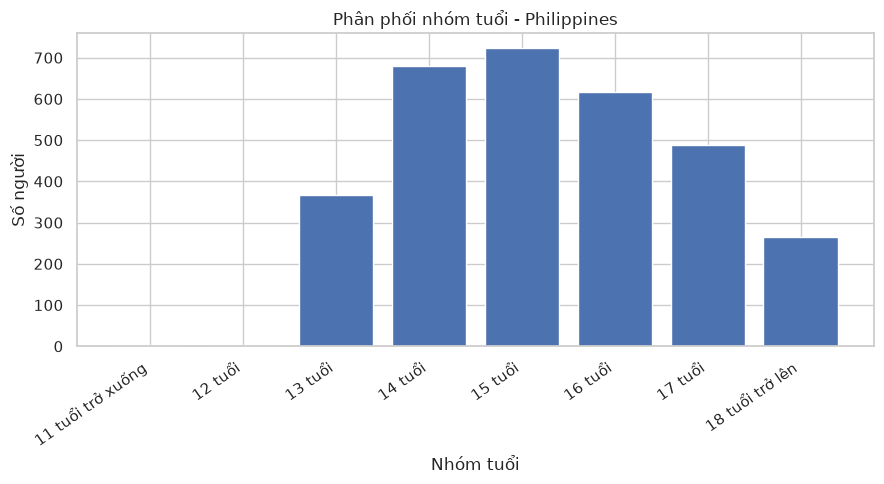

In [103]:
# Biểu đồ độ tuổi
plt.figure(figsize=(9, 5))
age_plot = eda["Q1"].map(age_labels).value_counts()
age_plot = age_plot.reindex(age_labels.values()).dropna()

plt.bar(age_plot.index, age_plot.values)
plt.title("Phân phối nhóm tuổi - Philippines")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Số người")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Nhận xét:
Mẫu khảo sát tập trung chủ yếu ở độ tuổi 14 đến 17. Nhóm 15 tuổi chiếm nhiều nhất (khoảng 23%), tiếp theo là nhóm 14 tuổi (khoảng 22%) và nhóm 16 tuổi (khoảng 20%).
Hai nhóm 11 tuổi trở xuống và 12 tuổi không có bản ghi nào trong dữ liệu.
Trong các nhóm có dữ liệu, nhóm 18 tuổi trở lên chiếm ít nhất (khoảng 8%), nhóm 13 tuổi chiếm khoảng 12%.
Phân phối có dạng gần chuông, đỉnh ở 15 tuổi, giảm dần ở các nhóm lớn tuổi hơn.

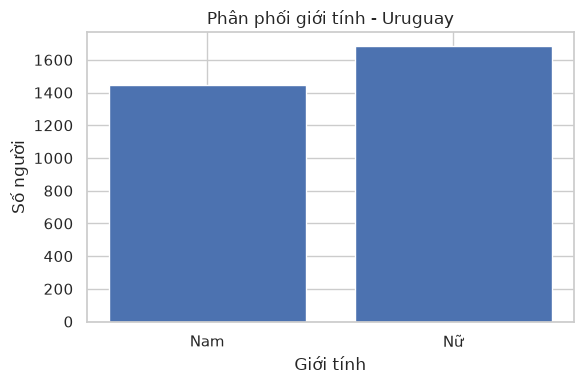

In [104]:
gender_plot = (
    eda["Q2"]
    .map(gender_labels)
    .value_counts()
    .reindex(["Nam", "Nữ"])
)

plt.figure(figsize=(6, 4))
plt.bar(gender_plot.index, gender_plot.values)
plt.title("Phân phối giới tính - Uruguay")
plt.xlabel("Giới tính")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

Nhận xét: - Tỷ lệ nữ (53,84%) nhiều hơn tỷ lệ nam (46,16%)

In [105]:
#Phân tích cô đơn, lo lắng và số bạn thân

def make_distribution_table(series):
    counts = series.value_counts().sort_index()
    table = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": (
            counts / counts.sum() * 100
        ).round(2)
    })
    return table

for question in ["Q22", "Q23", "Q27"]:
    print(f"\nPhân phối {question}:")
    display(make_distribution_table(eda[question]))


Phân phối Q22:


,Số lượng,Tỷ lệ (%)
Q22,,
1.0,830,26.33
2.0,807,25.60
3.0,1010,32.04
4.0,362,11.48
5.0,143,4.54



Phân phối Q23:


,Số lượng,Tỷ lệ (%)
Q23,,
1.0,895,28.52
2.0,943,30.05
3.0,935,29.80
4.0,276,8.80
5.0,89,2.84



Phân phối Q27:


,Số lượng,Tỷ lệ (%)
Q27,,
1.0,177,5.65
2.0,351,11.20
3.0,640,20.41
4.0,1967,62.74


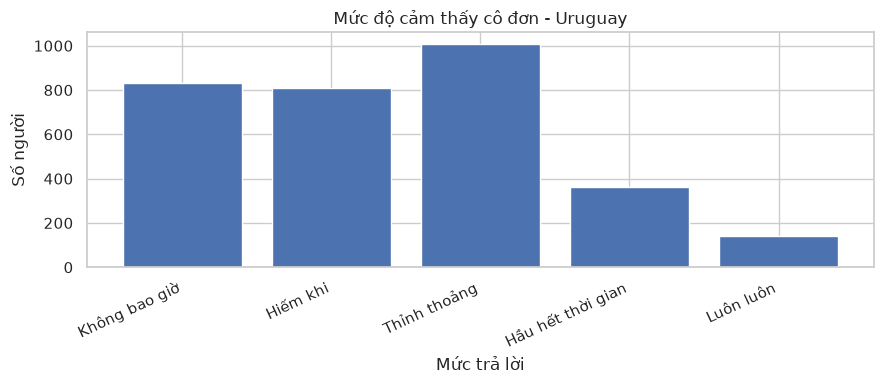

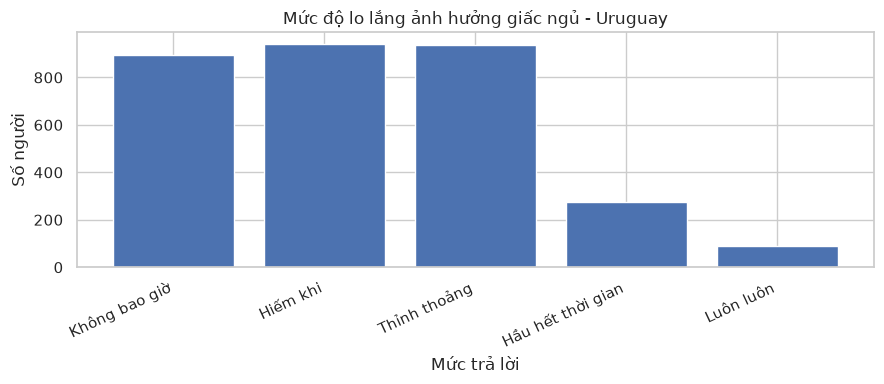

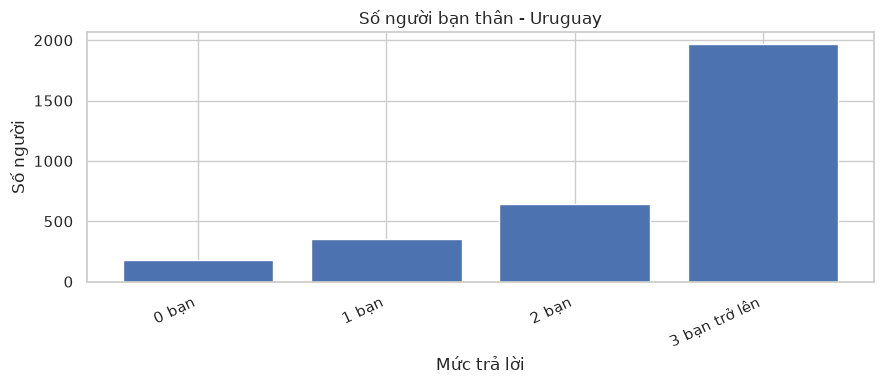

In [106]:
mental_labels = {
    "Q22": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q23": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q27": {
        1: "0 bạn",
        2: "1 bạn",
        3: "2 bạn",
        4: "3 bạn trở lên"
    }
}

plot_titles = {
    "Q22": "Mức độ cảm thấy cô đơn - Uruguay",
    "Q23": "Mức độ lo lắng ảnh hưởng giấc ngủ - Uruguay",
    "Q27": "Số người bạn thân - Uruguay"
}
for question in ["Q22", "Q23", "Q27"]:
    labels = mental_labels[question]
    counts = eda[question].value_counts().sort_index()
    x_labels = [
        labels.get(code, f"Mã {code}")
        for code in counts.index
    ]
    plt.figure(figsize=(9,4))
    plt.bar(x_labels, counts.values)
    plt.title(plot_titles[question])
    plt.xlabel("Mức trả lời")
    plt.ylabel("Số người")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

Nhận xét:

* Mức độ cảm thấy cô đơn: Nhiều nhất ở mức "Thỉnh thoảng" (khoảng 32,2%).
* Mức độ lo lắng ảnh hưởng giấc ngủ: Chủ yếu tập trung ở mức "Hiếm khi" và "Thỉnh thoảng" (mỗi mức chiếm khoảng 30,5%).
* Số người bạn thân: Đa số có từ "3 bạn trở lên" chiếm tới khoảng 62,8%.

In [107]:
 #Phân tích biến mục tiêu Q24
Q24_LABELS = {
    1: "Có",
    2: "Không"
}

# Chỉ thống kê các câu trả lời Q24 hợp lệ
q24_valid = eda["Q24"].isin([1,2])
q24 = eda.loc[q24_valid, "Q24"]

print("Tổng số dòng trong CSV:", len(eda))
print("Số câu trả lời Q24 hợp lệ:", int(q24_valid.sum()))
print("Số câu trả lời Q24 thiếu hoặc không hợp lệ:", int((~q24_valid).sum()))

q24_counts = q24.map(Q24_LABELS).value_counts()
q24_counts = q24_counts.reindex(["Có", "Không"], fill_value=0)

q24_table = pd.DataFrame({
    "Số lượng": q24_counts,
    "Tỷ lệ": (
        q24_counts / q24_counts.sum() * 100
    ).round(2)
})

print("\n Phân phối biến mục tiêu Q24:")
display(q24_table)

Tổng số dòng trong CSV: 3162
Số câu trả lời Q24 hợp lệ: 3119
Số câu trả lời Q24 thiếu hoặc không hợp lệ: 43

 Phân phối biến mục tiêu Q24:


,Số lượng,Tỷ lệ
Q24,,
Có,596,19.11
Không,2523,80.89


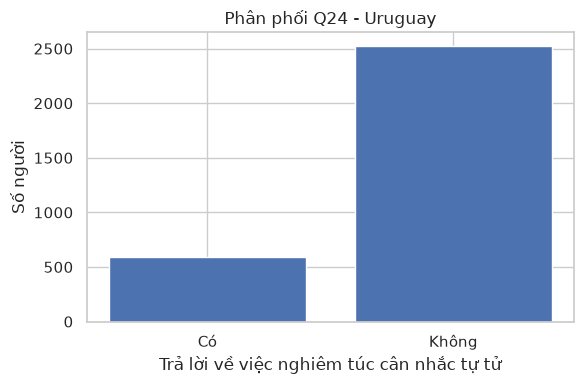

In [108]:
# Vẽ biểu đồ q24

plt.figure(figsize=(6,4))
plt.bar(
    q24_counts.index,
    q24_counts.values
)

plt.title("Phân phối Q24 - Uruguay")
plt.xlabel("Trả lời về việc nghiêm túc cân nhắc tự tử")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

In [109]:
# Kiểm tra mối liên hệ ban đầu với q24

eda_q24 = eda.loc[
    eda["Q24"].isin([1, 2])
].copy()

eda_q24["Q24_label"] = eda_q24["Q24"].map({
    1: "Có",
    2: "Không"
})

eda_q24["Q1_label"] = eda_q24["Q1"].map(age_labels)
eda_q24["Q2_label"] = eda_q24["Q2"].map(gender_labels)

# Thống kê Q24 theo nhóm tuổi
age_suicide_rate = (
    eda_q24.groupby("Q1")
    .agg(
        **{
            "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
            "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
        }
    )
    .reset_index()
)

# Tổng số người trong từng nhóm tuổi (Q1 hợp lệ)
age_suicide_rate["Tổng số người trong nhóm tuổi"] = (
    eda.groupby("Q1")["Q1"].count()
    .reindex(age_suicide_rate["Q1"])
    .to_numpy()
)

# Nhãn nhóm tuổi
age_suicide_rate["Nhóm tuổi"] = (
    age_suicide_rate["Q1"].map(age_labels)
)

# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
age_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    age_suicide_rate["Số trả lời Có"]
    / age_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
    age_suicide_rate[
        [
            "Nhóm tuổi",
            "Tổng số người trong nhóm tuổi",
            "Số trả lời Có",
            "Tổng trả lời hợp lệ Q24",
            "Tỷ lệ Q24 = Có (%)"
        ]
    ].round(2)
)
# Thống kê Q24 theo giới tính
gender_suicide_rate = (
    eda_q24.groupby("Q2")
        .agg(
            **{
                "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
                "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
            }
        )
        .reset_index()
)
# Tổng số người thuộc giới tính nam / nữ (Q1 hợp lệ)
gender_suicide_rate["Tổng số người theo giới tính"] = (
    eda.groupby("Q2")["Q2"].count()
    .reindex(gender_suicide_rate["Q2"])
    .to_numpy()
)
# Đổi mã giới tính thành nhãn
gender_suicide_rate["Giới tính"] = (
    gender_suicide_rate["Q2"].map(gender_labels)
)
# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
gender_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    gender_suicide_rate["Số trả lời Có"]
    / gender_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
   gender_suicide_rate[
           [
               "Giới tính",
               "Tổng số người theo giới tính",
               "Số trả lời Có",
               "Tổng trả lời hợp lệ Q24",
               "Tỷ lệ Q24 = Có (%)"
           ]
       ].round(2)
)

,Nhóm tuổi,Tổng số người trong nhóm tuổi,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,11 tuổi trở xuống,3,0,2,0.00
1,12 tuổi,4,0,4,0.00
2,13 tuổi,367,57,363,15.70
3,14 tuổi,681,131,667,19.64
4,15 tuổi,723,153,715,21.40
5,16 tuổi,617,121,610,19.84
6,17 tuổi,489,90,486,18.52
7,18 tuổi trở lên,265,42,261,16.09


,Giới tính,Tổng số người theo giới tính,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,Nam,1444,157,1427,11.0
1,Nữ,1684,430,1660,25.9


Qua phân tích dữ liệu khảo sát Uruguay, tỷ lệ trả lời Có đối với câu hỏi Q24 có sự khác biệt giữa các nhóm tuổi và giới tính. Nhóm 15 tuổi có tỷ lệ cao nhất trong các nhóm tuổi được khảo sát (21,40%), trong khi nhóm 11 tuổi trở xuống và 12 tuổi có tỷ lệ thấp nhất (0,00%). Theo giới tính, tỷ lệ ở nữ là 25,90%, cao hơn nam (11,00%).

# PHẦN 6. TIỀN XỬ LÝ DỮ LIỆU CHO MACHINE LEARNING

Mục tiêu:
- Chọn các biến đầu vào và biến mục tiêu.
- Kiểm tra giá trị thiếu và mã dữ liệu.
- Xử lý dữ liệu trước khi huấn luyện mô hình.
- Tránh sử dụng các biến gây rò rỉ thông tin mục tiêu.

In [110]:
# Chọn biến đầu vào và biến mục tiêu

FEATURES = ["Q1", "Q2", "Q15", "Q16", "Q17", "Q22", "Q23", "Q27"]
TARGET = "Q24"

#Tạo bản dữ liệu riêng cho Machine Learning
ml_data = eda[FEATURES + [TARGET]].copy()
print("Kích thước dữ liệu ban đầu:", ml_data.shape)
print("\n Số giá trị thiếu theo từng biến:")
display(ml_data.isna().sum().to_frame("Số giá trị thiếu"))
print("\n Phân phối biến mục tiêu Q24:")
display(ml_data[TARGET].value_counts(dropna=False).sort_index())

Kích thước dữ liệu ban đầu: (3162, 9)

 Số giá trị thiếu theo từng biến:


,Số giá trị thiếu
Q1,13
Q2,34
Q15,31
Q16,18
Q17,249
Q22,10
Q23,24
Q27,27
Q24,43



 Phân phối biến mục tiêu Q24:


Q24
1.0     596
2.0    2523
NaN      43
Name: count, dtype: int64

In [111]:
ml_clean = ml_data.copy()

#1. Chỉ giữ các dòng có Q24 hợp lệ: 1 = Có, 2 = Không
ml_clean = ml_clean.loc[
    ml_clean["Q24"].isin([1, 2])
].copy()

print("Kích thước sau khi loại Q24 thiếu", ml_clean.shape)

#2. Kiểm tra giá trị thiếu trong các biến đầu vào
print("\n Giá trị thiếu của các biến đầu vào:")
display(
    ml_clean[FEATURES]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
#3. Kiểm tra phân phối mục tiêu sau khi lọc
print("\n Phân phối Q24 sau khi lọc:")
display(ml_clean["Q24"].value_counts().sort_index())

Kích thước sau khi loại Q24 thiếu (3119, 9)

 Giá trị thiếu của các biến đầu vào:


,Số giá trị thiếu
Q1,11
Q2,32
Q15,29
Q16,18
Q17,241
Q22,5
Q23,19
Q27,20



 Phân phối Q24 sau khi lọc:


Q24
1.0     596
2.0    2523
Name: count, dtype: int64

In [112]:
# Điền giá trị thiếu ở các biến đầu vào
ml_imputed = ml_clean.copy()

for col in FEATURES:
    if ml_imputed[col].isna().any():
        mode_value = ml_imputed[col].mode(dropna=True)[0]
        ml_imputed[col] = ml_imputed[col].fillna(mode_value)

print("Kích thước sau khi xử lý:", ml_imputed.shape)
print("\n Số giá trị thiếu còn lại:")
display(
    ml_imputed[FEATURES + [TARGET]]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
print("\n Phân phối Q24:")
display(ml_imputed[TARGET].value_counts().sort_index())

Kích thước sau khi xử lý: (3119, 9)

 Số giá trị thiếu còn lại:


,Số giá trị thiếu
Q1,0
Q2,0
Q15,0
Q16,0
Q17,0
Q22,0
Q23,0
Q27,0
Q24,0



 Phân phối Q24:


Q24
1.0     596
2.0    2523
Name: count, dtype: int64

In [113]:
# Tạo nhãn mục tiêu nhị phân
ml_model = ml_imputed.copy()
# Q24: 1 = Có -> 1; 2 = Không -> 0
ml_model["Q24"] = ml_model["Q24"].map({
    1: 1,
    2: 0
}).astype(int)

print("Phân phối nhãn Q24:")
display(
    ml_model["Q24"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Không (0)", 1:"Có (1)"})
    .to_frame("Số người")
)
print("\n Tỷ lệ từng nhãn (%):")
display(
    (
        ml_model["Q24"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .rename(index={0: "Không (0)", 1: "Có (1)"})
        .round(2)
        .to_frame("Tỷ lệ (%)")
    )
)

Phân phối nhãn Q24:


,Số người
Q24,
Không (0),2523
Có (1),596



 Tỷ lệ từng nhãn (%):


,Tỷ lệ (%)
Q24,
Không (0),80.89
Có (1),19.11


Chia dữ liệu thành tập huấn luyện và kiểm tra

In [114]:
from sklearn.model_selection import train_test_split
# x: các biến đầu vào,  y: biến mục tiêu
x = ml_model[FEATURES].copy()
y = ml_model["Q24"].copy()

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Kích thước x_train:", x_train.shape)
print("Kích thước x_test:", x_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

print("\n Tỷ lệ nhãn trong tập train (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\n Tỷ lệ nhãn trong tập test (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

Kích thước x_train: (2495, 8)
Kích thước x_test: (624, 8)
Kích thước y_train: (2495,)
Kích thước y_test: (624,)

 Tỷ lệ nhãn trong tập train (%):


Q24
0    80.88
1    19.12
Name: proportion, dtype: float64


 Tỷ lệ nhãn trong tập test (%):


Q24
0    80.93
1    19.07
Name: proportion, dtype: float64

In [115]:
from sklearn.model_selection import train_test_split
# Tạo x và y từ dữ liệu chưa điền thiếu
x = ml_clean[FEATURES].copy()
# Q24: 1=Có, 2=Không
y = ml_clean["Q24"].map({1: 1, 2: 0}).astype(int)

# Chia train/test trước khi học giá trị điền thiếu
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("Giá trị thiếu trong x_train:", x_train.isna().sum().sum())
print("Giá trị thiếu trong x_test:", x_test.isna().sum().sum())

x_train: (2495, 8)
x_test: (624, 8)
Giá trị thiếu trong x_train: 294
Giá trị thiếu trong x_test: 81


## Chỉ số đánh giá mô hình 


- TN (True Negative) - Dự đoán âm tính đúng (dự đoán Không và thực tế cũng là Không)
- FP (False Positive)- Dự đoán dương tính sai (dự đoán Có và thực tế là Không)
- FN (False Negative)- Dự đoán âm tính sai (dự đoán Không và thực tế là Có)
- TP (True Positive) - Dự đoán dương tính đúng (dự đoán Có và thực tế cũng là Có)

- Accuracy - Độ chính xác tổng thể = $\frac{TP + TN}{TP + TN + FP + FN}$
- Precision - Độ chính xác của dự đoán Có = $\frac{TP}{TP + FP}$
- Recall - Khả năng nhận diện nhóm Có = $\frac{TP}{TP + FN}$
- F1-score - Chỉ số đánh giá mô hình Machine Learning = 2 x $\frac{Precision * Recall}{Precision + Recall}$
- ROC-AUC - Chỉ số đo lường khả năng phân biệt hai lớp của mô hình phân loại :


    - ROC-AUC là diện tích đường cong ROC(Receiver Operating Characteristic)

    - Đường ROC biểu diễn mối quan hệ giữa: 

        + TPR (True Positive Rate)- chính là Recall = $\frac{TP}{TP + FN}$


        + FPR(False Positive Rate)- tỷ lệ dự đoán nhầm nhóm Không thành Có = $\frac{FP}{FP + TN}$

    - ROC-AUC được tính bằng tích phân: $$AUC_{ROC} = \int_0^1 TPR(FPR) \, d(FPR)$$
- RP-AUC - Chỉ số đánh giá hiệu quả của mô hình phân loại:


    - PR-AUC(Precision-Recall Area Under the Curve) là diện tích dưới đường cong Precision-Recall
    $$AUC_{PR} = \int_0^1 Precision(Recall) \, d(Recall)$$


# Xây dựng mô hình Logistic Regression đầu tiên

In [116]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

SimpleImputer(strategy="most_frequent"): điền giá trị thiếu bằng mã trả lời xuất hiện nhiều nhất, được tính từ tập train.



StandardScaler(): chuẩn hóa thang đo các biến đầu vào.



LogisticRegression(): học cách phân loại Q24 thành 0 = Không hoặc 1 = Có.



fit(x_train, y_train): chỉ huấn luyện trên tập train; tập test được giữ riêng để đánh giá.

In [117]:
# Pipeline: điền giá trị thiếu -> chuẩn hóa -> huấn luyện
logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])
# Huấn luyện chỉ trên tập train
logistic_model.fit(x_train, y_train)
print("Đã huấn luyện Logistic Regression thành công!")

Đã huấn luyện Logistic Regression thành công!


In [118]:
# Dự đoán trên tập test
y_pred = logistic_model.predict(x_test)
print("Số dự đoán:", len(y_pred))
print("10 nhãn thực tế đầu tiên:", y_test.iloc[:10].tolist())
print("10 nhãn dự đoán đầu tiên:", y_pred[:10].tolist())

Số dự đoán: 624
10 nhãn thực tế đầu tiên: [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
10 nhãn dự đoán đầu tiên: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


# Đánh giá mô hình Logistic Regression

In [119]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_auc_score

)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

df_report = pd.DataFrame(report).transpose()

display(df_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - LOGISTIC REGRESSION")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))

,precision,recall,f1-score,support
Không (0),0.8554,0.9723,0.9101,505.000000
Có (1),0.7200,0.3025,0.4260,119.000000
accuracy,0.8446,0.8446,0.8446,0.844551
macro avg,0.7877,0.6374,0.6681,624.000000
weighted avg,0.8296,0.8446,0.8178,624.000000


Nhận xét:

* Mô hình Logistic Regression đạt Accuracy = 84.46%
* Phân loại tốt nhóm Không với Recall = 97.23% và F1-score = 0.9101
* Tuy nhiên, nhóm Có có Recall chỉ đạt 30.25% và F1-score = 0.4260, cho thấy mô hình còn bỏ sót nhiều trường hợp thực tế

--> Nhìn chung, mô hình có độ chính xác tổng thể cao nhưng chưa nhận diện tốt nhóm thiểu số, cần cải thiện để cân bằng khả năng phân loại giữa hai nhóm

In [120]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
nn_proba = nn_model.predict(x_test_dl, verbose=0).ravel()
# Chuyển xác suất thành nhãn 0 hoặc 1
nn_pred = (nn_proba >= 0.5).astype(int)
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred, zero_division=0),
    "Recall": recall_score(y_test, nn_pred, zero_division=0),
    "F1-score": f1_score(y_test, nn_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, nn_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, nn_proba)
}
print("NEURAL NETWORK")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


ValueError: X has 43 features, but SimpleImputer is expecting 8 features as input.

* Accuracy = 0,7933: Mô hình dự đoán đúng khoảng 79,33% tổng số mẫu.
* Precision = 0,4675: Trong số những mẫu được dự đoán Có, khoảng 46,75% thực tế thuộc nhóm Có.
* Recall = 0,6050: Mô hình nhận diện được khoảng 60,50% số mẫu thực tế thuộc nhóm Có.
* F1-score = 0,5275: Đạt mức trung bình khá, thể hiện sự cân bằng tốt hơn giữa Precision và Recall so với các mô hình trước.
* ROC-AUC = 0,8000: Mô hình có khả năng phân biệt hai nhóm ở mức tốt.
* PR-AUC = 0,5674: Khả năng xếp hạng và nhận diện nhóm Có được cải thiện rõ rệt ở các ngưỡng dự đoán khác nhau.

## TỔNG HỢP VÀ SO SÁNH 5 MÔ HÌNH MACHINE LEARNING VÀ DEEP LEARNING

In [ ]:
# Tổng hợp kết quả 5 mô hình
comparison_data = [
    {
        "Mô hình": "Logistic Regression",
        "Accuracy": 0.8123,
        "Precision": 0.6667,
        "Recall": 0.1008,
        "F1-score": 0.1752,
        "ROC-AUC": 0.7346,
        "PR-AUC": 0.4387
    },
    {
        "Mô hình": "Decision Tree",
        "Accuracy": 0.6960,
        "Precision": 0.3202,
        "Recall": 0.4790,
        "F1-score": 0.3838,
        "ROC-AUC": 0.6640,
        "PR-AUC": 0.3208
    },
    {
        "Mô hình": "Random Forest",
        "Accuracy": 0.6877,
        "Precision": 0.3365,
        "Recall": 0.5966,
        "F1-score": 0.4303,
        "ROC-AUC": 0.7100,
        "PR-AUC": 0.4033
    },
    {
        "Mô hình": "Gradient Boosting",
        "Accuracy": 0.8156,
        "Precision": 0.6429,
        "Recall": 0.1513,
        "F1-score": 0.2449,
        "ROC-AUC": 0.7183,
        "PR-AUC": 0.4109
    },
    {
        "Mô hình": "Neural Network",
        "Accuracy": 0.8090,
        "Precision": 0.5833,
        "Recall": 0.1176,
        "F1-score": 0.1958,
        "ROC-AUC": 0.7029,
        "PR-AUC": 0.4009
    }
]

comparison_data = [
    evaluate("Logistic Regression", lr_model.predict_proba(x_test)[:, 1]),
    evaluate("Decision Tree",       dt_model.predict_proba(x_test)[:, 1]),
    evaluate("Random Forest",       rf_model.predict_proba(x_test)[:, 1]),
    evaluate("Gradient Boosting",   gb_model.predict_proba(x_test)[:, 1]),
    evaluate("Neural Network",      nn_model.predict_proba(x_test)[:, 1]),
]

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.round(4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7468,0.4067,0.7143,0.5183,0.8145,0.5715
1,Decision Tree,0.8189,0.5242,0.5462,0.5350,0.7761,0.4747
2,Random Forest,0.7644,0.4125,0.5546,0.4731,0.7551,0.4310
3,Gradient Boosting,0.8429,0.6909,0.3193,0.4368,0.8237,0.5822
4,Neural Network,0.8429,0.6667,0.3529,0.4615,0.8126,0.5709


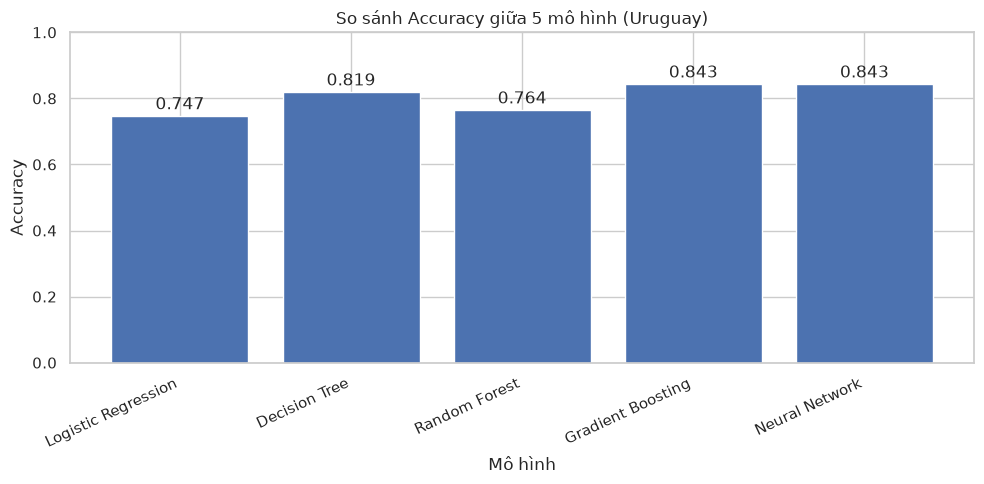

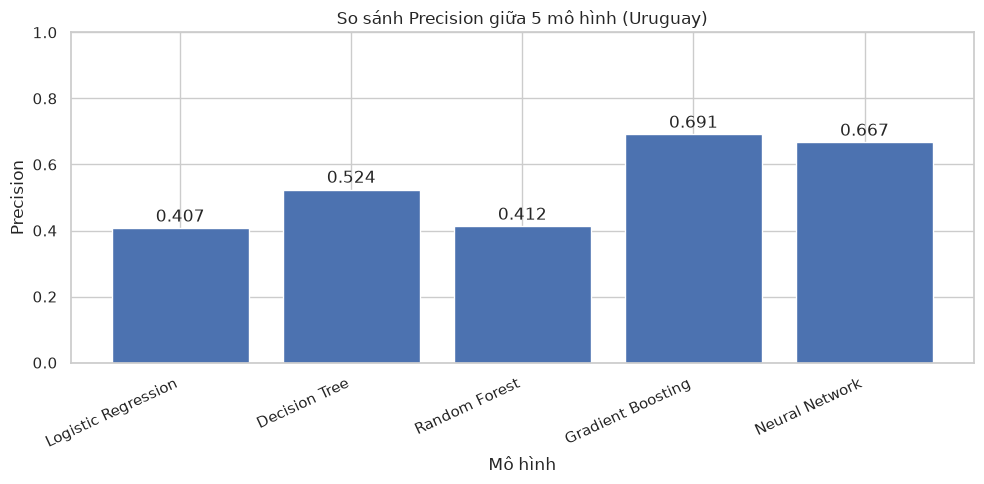

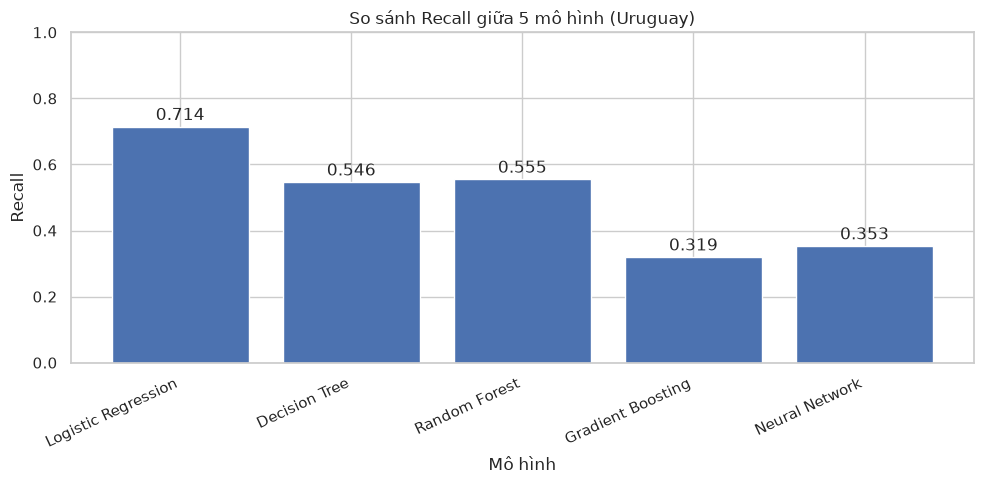

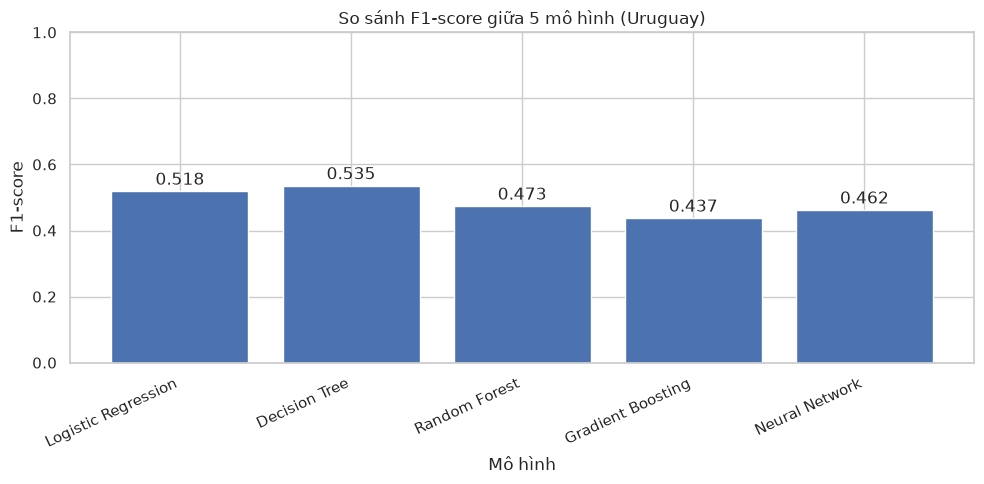

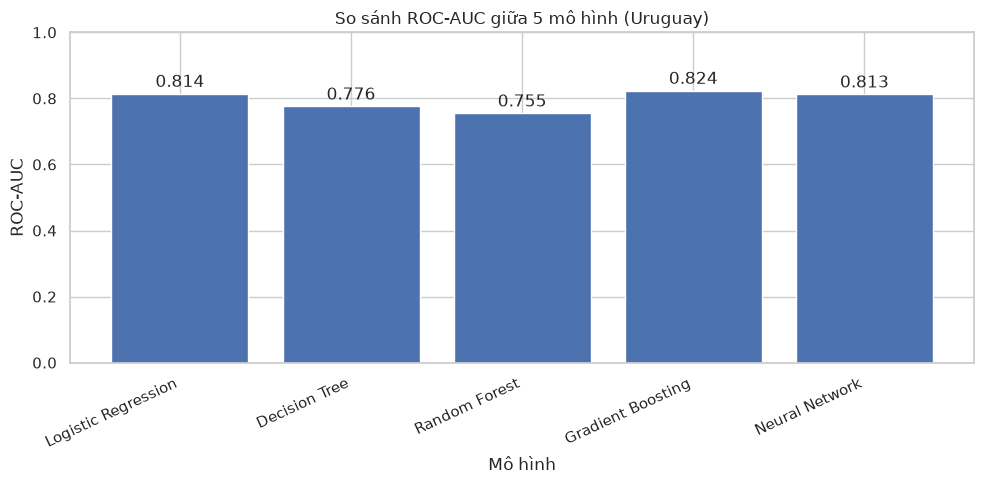

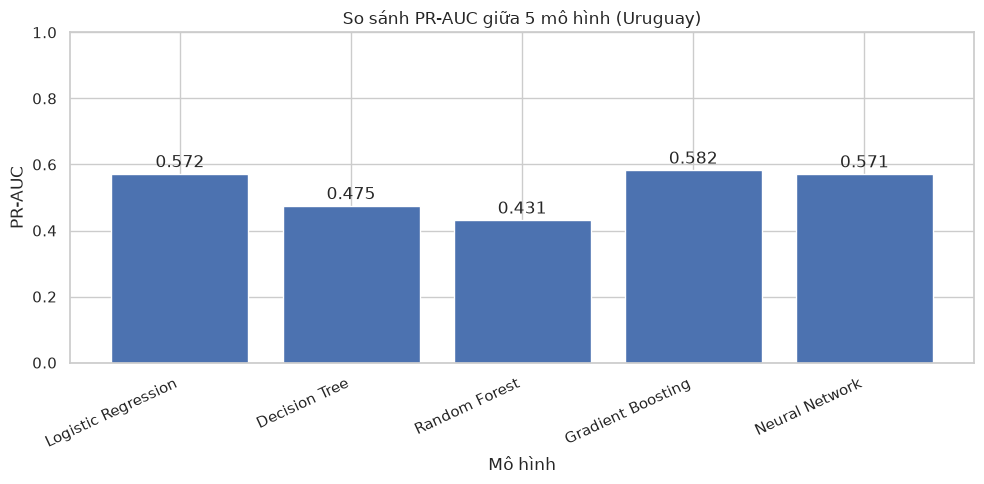

In [ ]:
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    bars = plt.bar(comparison_df["Mô hình"], comparison_df[metric])
    plt.bar_label(bars, fmt="%.3f", padding=2)
    plt.title(f"So sánh {metric} giữa 5 mô hình (Uruguay)")
    plt.xlabel("Mô hình")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

In [ ]:
for metric in metrics_to_plot:
    best_idx = comparison_df[metric].idxmax()

    print(
        f"{metric}: {comparison_df.loc[best_idx, 'Mô hình']}"
        f"({comparison_df.loc[best_idx, metric]:.4f})"
    )

Accuracy: Gradient Boosting(0.8429)
Precision: Gradient Boosting(0.6909)
Recall: Logistic Regression(0.7143)
F1-score: Decision Tree(0.5350)
ROC-AUC: Gradient Boosting(0.8237)
PR-AUC: Gradient Boosting(0.5822)


Nhận xét:

* Gradient Boosting có Accuracy cao nhất (84,29%), Precision cao nhất (69,09%), ROC-AUC cao nhất (0,8237) và PR-AUC cao nhất (0,5822).
* Decision Tree có F1-score cao nhất (0,5350 hoặc 53,50%).
* Logistic Regression có Recall cao nhất (0,7143 hoặc 71,43%), giúp phát hiện nhiều trường hợp thuộc nhóm Có nhất.
* Cả 5 mô hình đều có sự đánh đổi giữa Precision và Recall.

--> Nếu mục tiêu là ưu tiên phát hiện nhiều trường hợp thuộc nhóm Có nhất, Logistic Regression là ứng viên đáng xem xét nhất nhờ chỉ số Recall vượt trội. Nếu cần sự cân bằng giữa Precision và Recall, Decision Tree là lựa chọn phù hợp nhất với F1-score cao nhất.

## CẢI THIỆN MÔ HÌNH RANDOM FOREST

In [ ]:
import numpy as np
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, roc_auc_score
)

# Lấy xác suất dự đoán nhóm Có (Q24 = 1)
rf_proba = rf_model.predict_proba(x_test)[:, 1]

print("Đã lấy xác suất dự đoán!")
print("5 xác suất đầu tiên:", rf_proba[:5])

Đã lấy xác suất dự đoán!
5 xác suất đầu tiên: [0.03276515 0.1180398  0.10333333 0.68550631 0.19614186]


In [ ]:
#Thử nhiều ngưỡng dự đoán
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:
    rf_pred_threshold = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Ngưỡng": threshold,
        "Accuracy": accuracy_score(y_test, rf_pred_threshold),
        "Precision": precision_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, rf_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Ngưỡng,Accuracy,Precision,Recall,F1-score
0,0.2,0.6058,0.3034,0.8235,0.4434
1,0.3,0.6699,0.3320,0.7227,0.4550
2,0.4,0.7260,0.3750,0.6555,0.4771
3,0.5,0.7644,0.4125,0.5546,0.4731
4,0.6,0.7933,0.4569,0.4454,0.4511


Vẽ biểu đồ so sánh

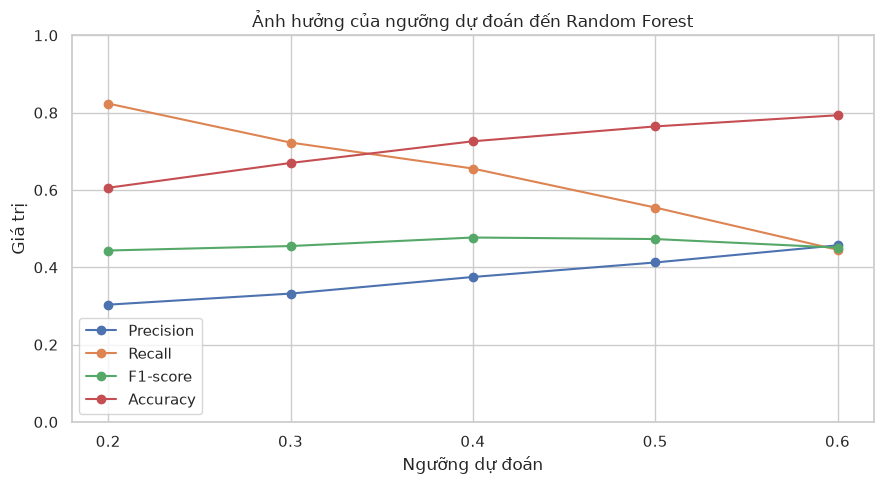

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1-score", "Accuracy"]:
    plt.plot(
        threshold_df["Ngưỡng"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.title("Ảnh hưởng của ngưỡng dự đoán đến Random Forest")
plt.xlabel("Ngưỡng dự đoán")
plt.ylabel("Giá trị")
plt.xticks(thresholds)
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Nhận xét kết quả điều chỉnh ngưỡng Random Forest:

* Khi giảm ngưỡng dự đoán (về 0,2), Recall tăng cao nhất (khoảng 0,82), giúp mô hình phát hiện được nhiều trường hợp Có hơn; tuy nhiên, Precision có xu hướng giảm (xuống khoảng 0,30).
* Khi tăng ngưỡng dự đoán (lên 0,6), Precision tăng dần (đạt khoảng 0,46) và Accuracy tăng (đạt gần 0,80), nhưng Recall giảm mạnh (xuống khoảng 0,44), khiến mô hình bỏ sót nhiều trường hợp Có hơn.
* F1-score đạt giá trị cao nhất và ổn định tại hai ngưỡng 0,4 và 0,5 (đạt khoảng 0,48), sau đó giảm nhẹ xuống 0,45 ở ngưỡng 0,6.

Kết luận: Với mục tiêu cân bằng giữa Precision và Recall, ngưỡng 0,4 hoặc 0,5 là lựa chọn tốt nhất trong các ngưỡng đã thử. Tuy nhiên, nếu ưu tiên phát hiện tối đa các trường hợp Có, cần cân nhắc chọn ngưỡng thấp hơn (như 0,2 hoặc 0,3) dựa trên mức Precision và Recall chấp nhận được.

,Đặc trưng,Mức độ quan trọng
0,Q22,0.2594
1,Q1,0.1854
2,Q23,0.1748
3,Q17,0.1007
4,Q27,0.0868
5,Q15,0.0762
6,Q16,0.0683
7,Q2,0.0483


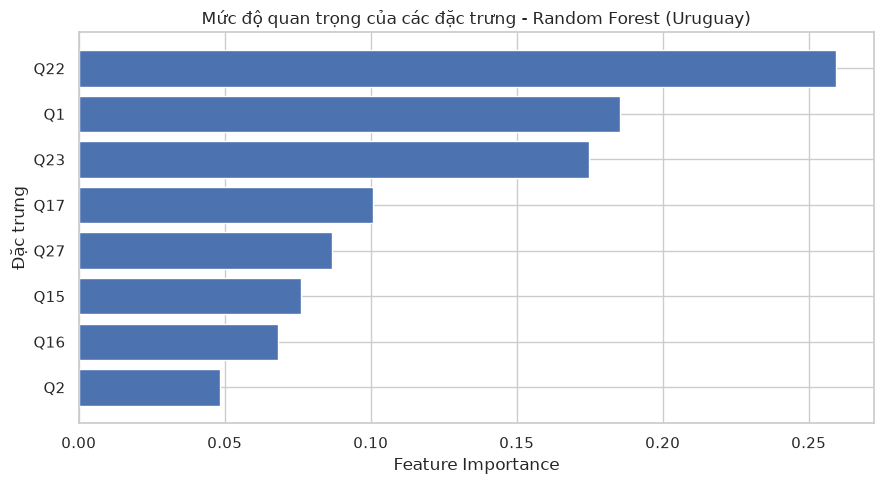

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

TARGET = "q24"
FEATURES = ["q1", "q2", "q15", "q16", "q17", "q22", "q23", "q27"]

# 1. Dữ liệu chỉ gồm 8 đặc trưng + biến mục tiêu
data = df[FEATURES + [TARGET]].apply(pd.to_numeric, errors="coerce")
data = data.dropna(subset=[TARGET])

X = data[FEATURES]
y = (data[TARGET] == 1).astype(int)

# 2. Chia train/test
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# 3. Huấn luyện lại Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_model.fit(x_train, y_train)

# 4. Bảng mức độ quan trọng
feature_importance = pd.DataFrame({
    "Đặc trưng": [c.upper() for c in x_train.columns],
    "Mức độ quan trọng": rf_model.named_steps["rf"].feature_importances_
}).sort_values(by="Mức độ quan trọng", ascending=False).reset_index(drop=True)

display(feature_importance.round(4))

# 5. Biểu đồ
plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Đặc trưng"][::-1],
         feature_importance["Mức độ quan trọng"][::-1])
plt.title("Mức độ quan trọng của các đặc trưng - Random Forest (Uruguay)")
plt.xlabel("Feature Importance")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

Nhận xét Feature Importance:

* Q22 = 0,2594, Q1 = 0,1854 và Q23 = 0,1748: Là ba đặc trưng quan trọng nhất, đóng góp lớn nhất vào kết quả dự đoán của mô hình Random Forest.
* Q17, Q27, Q15 và Q16: Có mức độ quan trọng trung bình, dao động khoảng 0,068–0,101.
* Q2 = 0,0483: Có mức độ quan trọng thấp nhất trong 8 đặc trưng.

Kết luận: Q22, Q1 và Q23 là các biến đóng góp nhiều nhất vào khả năng dự đoán của mô hình, trong khi Q2 đóng góp ít nhất. Tuy nhiên, Feature Importance chỉ phản ánh mức độ đóng góp vào dự đoán, không chứng minh các biến này có quan hệ nhân quả với kết quả Q24.

## TỔNG KẾT KẾT QUẢ 5 MÔ HÌNH

## KẾT LUẬN

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

def evaluate(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    }

comparison_df = pd.DataFrame([
    evaluate("Random Forest",       rf_model.predict_proba(x_test)[:, 1]),
    evaluate("Decision Tree",       dt_model.predict_proba(x_test)[:, 1]),
    evaluate("Gradient Boosting",   gb_model.predict_proba(x_test)[:, 1]),
    evaluate("Neural Network",      nn_model.predict_proba(x_test)[:, 1]),
    evaluate("Logistic Regression", lr_model.predict_proba(x_test)[:, 1]),
])
display(comparison_df.round(4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,0.7644,0.4125,0.5546,0.4731,0.7551,0.4310
1,Decision Tree,0.8189,0.5242,0.5462,0.5350,0.7761,0.4747
2,Gradient Boosting,0.8429,0.6909,0.3193,0.4368,0.8237,0.5822
3,Neural Network,0.8429,0.6667,0.3529,0.4615,0.8126,0.5709
4,Logistic Regression,0.7468,0.4067,0.7143,0.5183,0.8145,0.5715


# KẾT LUẬN

Qua quá trình thử nghiệm 5 mô hình, Decision Tree đạt kết quả tốt nhất về F1-score (0,5350), trong khi Logistic Regression đạt Recall cao nhất (0,7143), cho thấy khả năng nhận diện nhóm Có tốt hơn các mô hình còn lại. Gradient Boosting và Neural Network đạt Accuracy cao nhất (0,8429), đồng thời Gradient Boosting cũng sở hữu ROC-AUC (0,8237) và PR-AUC (0,5822) cao nhất. Kết quả cho thấy chưa có mô hình nào vượt trội trên tất cả các chỉ số. Decision Tree và Logistic Regression là các lựa chọn đáng cân nhắc tùy thuộc vào mục tiêu ưu tiên cân bằng hay phát hiện nhóm Có, tuy nhiên vẫn cần cải thiện hiệu quả phân loại và đánh giá thêm trước khi áp dụng thực tế.
```[cite: 20, 21]